# **Titanic Passenger Survival Prediction**
# **Problem Statement**
During the Titanic disaster, passenger survival was influenced by factors such as age, gender,
and passenger class.

The objective of this project is to build a **binary classification machine learning model** to
predict whether a passenger survived (Yes/No) using historical passenger data and to identify
the most important factors affecting surviva

# **Objectives of the Project**
· Understand passenger survival patterns

· Perform basic data preprocessing

· Conduct **minimal but meaningful EDA**

· Build binary classification models

· Evaluate model performance

. Identify key survival-influencing features

Load Database

In [ ]:
#uploading file
from google.colab import files
uploaded=files.upload()


Saving train.csv to train.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier


In [ ]:
#Reading  the Dataset
df=pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.duplicated().sum()

np.int64(0)

# **Exploratory Data Analysis (EDA) - Minimal Graphs**
**Graph 1:** **Survival Count Plot**

**Purpose:**
* Understand class distribution
* Confirm binary classification nature

**Graph:**
* Bar chart: Survived vs Not Survived

/tmp/ipython-input-1759349658.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Survived", data=df, palette="Set2")


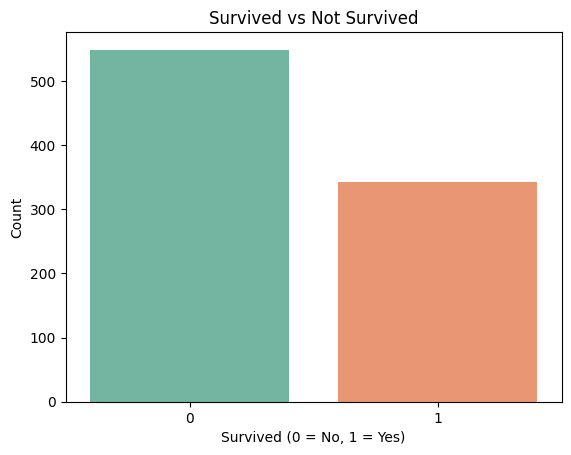

In [ ]:
sns.countplot(x="Survived", data=df, palette="Set2")
plt.title("Survived vs Not Survived")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Graph 2**: **Survival by Gender**

**Purpose**:
*  Analyze impact of gender on survival

**Graph**:

· Analyze impact of gender on survival

· Bar chart

· **X-axis**: *Sex*

· **Hue**: *Survived*

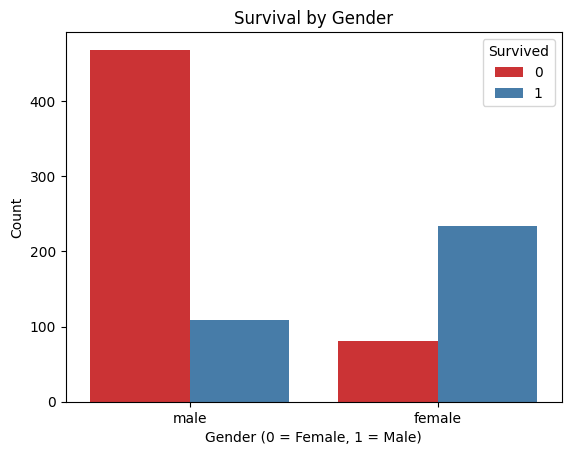

In [ ]:
sns.countplot(x="Sex", hue="Survived", data=df, palette="Set1")
plt.title("Survival by Gender")
plt.xlabel("Gender (0 = Female, 1 = Male)")
plt.ylabel("Count")
plt.show()

**Graph 3: Survival by Passenger Class**

**Purpose:**
* Understand effect of socio-economic status

**Graph 3:**

· Bar chart

· **X-axis:** *Pclass*

· **Hue:** *Survived*

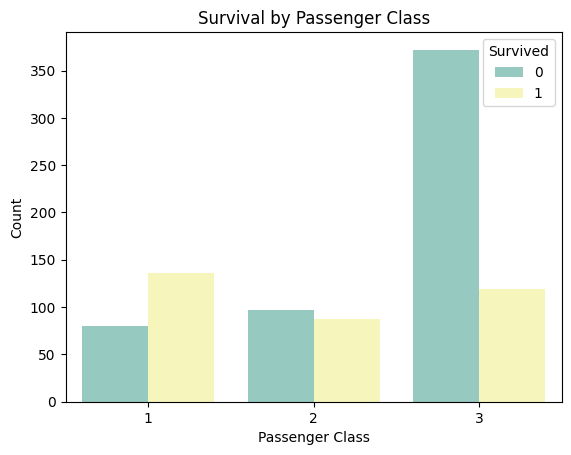

In [ ]:
sns.countplot(x="Pclass", hue="Survived", data=df, palette="Set3")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

**Graph 4: Fare vs Survival**

**Purpose:**

* Analyze relationship between ticket fare and survival

**Graph:**

* Box plot
* **X-axis:** *Survived*
* **Y-axis:** *Fare*


/tmp/ipython-input-1517249545.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Survived", y="Fare", data=df, palette="coolwarm")


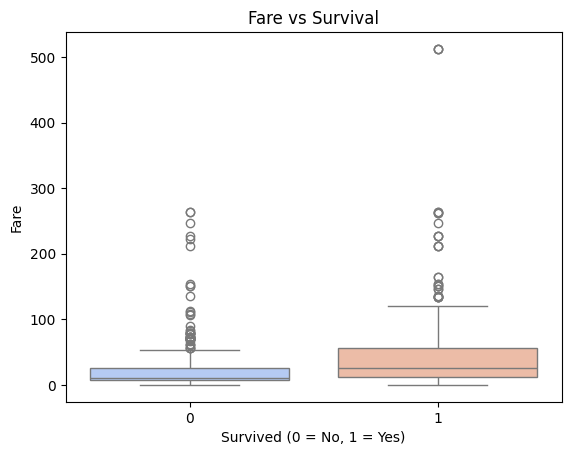

In [ ]:
sns.boxplot(x="Survived", y="Fare", data=df, palette="coolwarm")
plt.title("Fare vs Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

# **Machine Learning Workflow**

**Hndle missing values**

In [ ]:
#Checking missing values
df.isnull().sum()

NameError: name 'df' is not defined

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
cols=['Survived','Pclass','Sex','Age','Ticket','Embarked']
df[cols]

,Survived,Pclass,Sex,Age,Ticket,Embarked
0,0,3,male,22.0,A/5 21171,S
1,1,1,female,38.0,PC 17599,C
2,1,3,female,26.0,STON/O2. 3101282,S
3,1,1,female,35.0,113803,S
4,0,3,male,35.0,373450,S
...,...,...,...,...,...,...
886,0,2,male,27.0,211536,S
887,1,1,female,19.0,112053,S
888,0,3,female,NaN,W./C. 6607,S
889,1,1,male,26.0,111369,C


In [ ]:
df.drop('Cabin', axis=1, inplace=True)

In [ ]:
df['Age']=df['Age'].fillna(df['Age'].median())

df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode())

In [ ]:
#binary Encoded
df['Sex']=df['Sex'].map({'male':0,'female':1})

In [ ]:
from sklearn.preprocessing import LabelEncoder
#Label encoded
le=LabelEncoder()
df['Embarked']=le.fit_transform(df['Embarked'])

In [ ]:
#Scaling Numerical Features

scaler = StandardScaler()
numeric_cols = ['Age', 'Fare']
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [ ]:
x=df[['Pclass','Age','Sex','Embarked']]
y=df['Survived']

x_train,x_test,y_train,y_test=train_test_split(
    x,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
#Training Logistic Regression Model

model_lg = LogisticRegression()
model_lg.fit(x_train, y_train)

y_pred = model_lg.predict(x_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))



Logistic Regression Accuracy: 0.770949720670391
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



In [ ]:
#Training Decicsion Tree model
model_dt = DecisionTreeClassifier(criterion='gini', max_depth=3)
model_dt.fit(x_train, y_train)

y_pred = model_dt.predict(x_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred))
print(print("Classification Report:\n", classification_report(y_test, y_pred)))


Decision Tree Accuracy: 0.776536312849162
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.92      0.83       110
           1       0.81      0.55      0.66        69

    accuracy                           0.78       179
   macro avg       0.79      0.73      0.74       179
weighted avg       0.78      0.78      0.77       179

None


In [ ]:
#Train Random Forest Model
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_rf.fit(x_train, y_train)
y_pred = model_rf.predict(x_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Random Forest Accuracy: 0.7988826815642458
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.88      0.84       110
           1       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.7988826815642458
Precision: 0.7796610169491526
Recall   : 0.6666666666666666
F1-score : 0.71875


In [ ]:
y_pred = model_rf.predict(x_test)

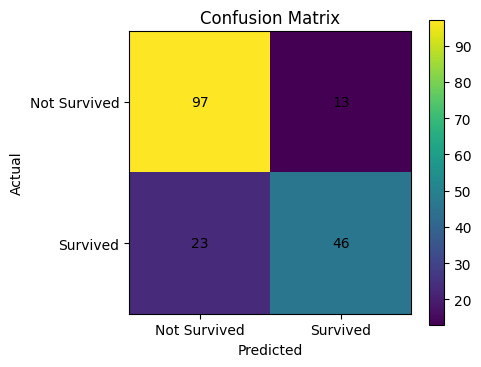

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['Not Survived', 'Survived'])
plt.yticks([0, 1], ['Not Survived', 'Survived'])

# Print values inside cells
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

importances = model_rf.feature_importances_

feature_names = x.columns

indices = np.argsort(importances)[::-1]

# **Identifying Survival-Influencing Factors**
**Graph 6:**

Feature Importance (Random Forest)

**Purpose:**

* Identify most influential survival factors

**Graph:**

* Bar chart of feature importance

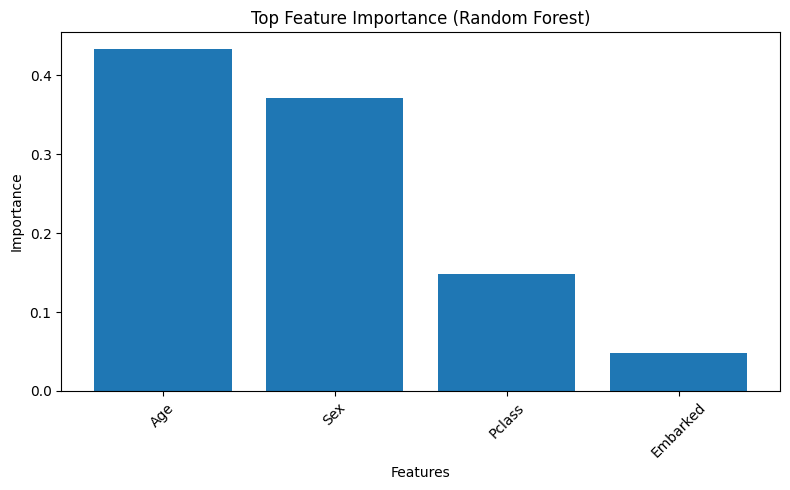

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(
    range(len(feature_names)),
    feature_names[indices],
    rotation=45
)
plt.title("Top Feature Importance (Random Forest)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()